In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == 'notebooks':
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / 'data' / 'processed'

In [5]:
df_train = pd.read_csv(DATA_DIR / 'train.csv')
df_val = pd.read_csv(DATA_DIR / 'val.csv')

y_train = pd.read_csv(DATA_DIR / 'y_train.csv').values.ravel()
y_val = pd.read_csv(DATA_DIR / 'y_val.csv').values.ravel()

## Decision Tree

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [7]:
train_dicts = df_train.to_dict(orient='records')

In [8]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [9]:
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [10]:
for d in [1,2,3,4,5,7,10,15,20,None]:
    dt = DecisionTreeClassifier(max_depth = d)
    dt.fit(X_train,y_train)

    y_pred = dt.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (d, auc))

   1 -> 0.674
   2 -> 0.780
   3 -> 0.795
   4 -> 0.804
   5 -> 0.802
   7 -> 0.795
  10 -> 0.762
  15 -> 0.654
  20 -> 0.620
None -> 0.657


##### so max_depth of 4 is good, with auc of 80.4%. but can consider 3, 4, 5 for further steps

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

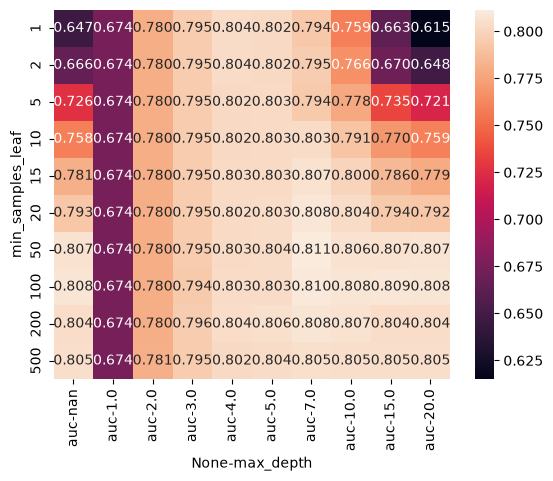

In [11]:
scores = []

for d in [1,2,3,4,5,7,10,15,20,None]:
    for s in [1,2,5,10,15,20,50,100,200,500]:
        dt = DecisionTreeClassifier(max_depth = d, min_samples_leaf=s)
        dt.fit(X_train,y_train)

        y_pred = dt.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d,s,auc))
df_scores = pd.DataFrame(scores, columns = ['max_depth','min_samples_leaf','auc'])
df_scores.sort_values(by='auc',ascending = False)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(5)
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

##### seems that max_depth=7 and min_sample_leaf=50 produces max auc of 81.1%

## Random Forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

In [13]:
rf = RandomForestClassifier(n_estimators=10,random_state=1) # n_estimators = number of models we want to use
rf.fit(X_train,y_train)

y_pred = rf.predict_proba(X_val)[:,1]
roc_auc_score(y_val, y_pred)

0.7853717969015863

In [14]:
for n in range(10,201,10):
    rf = RandomForestClassifier(n_estimators=n,random_state=2)
    rf.fit(X_train,y_train)

    y_pred = rf.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (n, auc))

  10 -> 0.784
  20 -> 0.798
  30 -> 0.803
  40 -> 0.804
  50 -> 0.805
  60 -> 0.806
  70 -> 0.807
  80 -> 0.805
  90 -> 0.806
 100 -> 0.806
 110 -> 0.805
 120 -> 0.806
 130 -> 0.805
 140 -> 0.806
 150 -> 0.806
 160 -> 0.805
 170 -> 0.805
 180 -> 0.805
 190 -> 0.805
 200 -> 0.806


In [15]:
for d in [5,10,15,20,50]:
    rf = RandomForestClassifier(n_estimators=70,max_depth=d, random_state=2)
    rf.fit(X_train,y_train)

    y_pred = rf.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.6f' % (d, auc))

   5 -> 0.808832
  10 -> 0.808162
  15 -> 0.811764
  20 -> 0.811762
  50 -> 0.804654


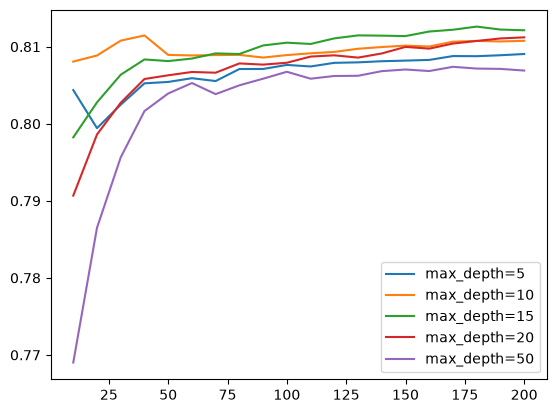

In [16]:
scores = []

for d in [5,10,15,20,50]:
	for n in range(10,201,10):
		rf= RandomForestClassifier(n_estimators=n, max_depth=d,random_state=1)
		rf.fit(X_train,y_train)
		
		y_pred = rf.predict_proba(X_val)[:,1]
		auc = roc_auc_score(y_val, y_pred)
		scores.append((d,n,auc))

df_scores = pd.DataFrame(scores,columns=['max_depth','n_estimators','auc'])
for d in [5,10,15,20,50]:
	df_subset = df_scores[df_scores.max_depth == d]
	plt.plot(df_subset.n_estimators,df_subset.auc, label = 'max_depth=%d' % d)
plt.legend()

##### n_estimator=175, max_depth=15, for auc=81.5%

In [17]:
max_depth = 15

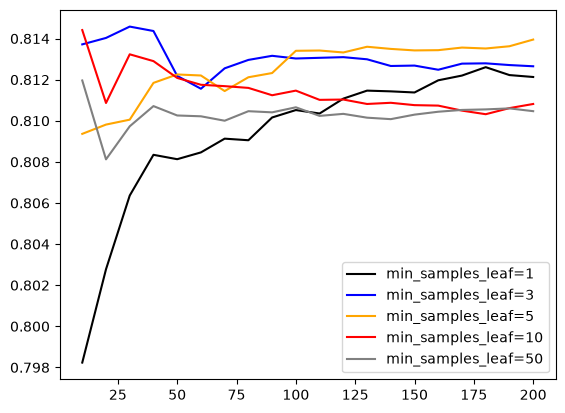

In [18]:
scores = []
for s in [1,3,5,10,50]:
	for n in range(10,201,10):
		rf= RandomForestClassifier(n_estimators=n, max_depth=max_depth,min_samples_leaf=s,random_state=1)
		rf.fit(X_train,y_train)
		
		y_pred = rf.predict_proba(X_val)[:,1]
		auc = roc_auc_score(y_val, y_pred)
		scores.append((s,n,auc))

df_scores = pd.DataFrame(scores,columns=['min_samples_leaf','n_estimators','auc'])

colors = ['black','blue','orange','red','grey']
min_samples_leaf = [1,3,5,10,50]
for s, col in list(zip(min_samples_leaf,colors)):
	df_subset=df_scores[df_scores.min_samples_leaf==s]
	plt.plot(df_subset.n_estimators,df_subset.auc, color = col, label = 'min_samples_leaf=%d' % s)
plt.legend()

In [19]:
df_scores.sort_values('auc', ascending=False).head(10).reset_index(drop=True)

,min_samples_leaf,n_estimators,auc
0,3,30,0.814583
1,10,10,0.814414
2,3,40,0.814368
3,3,20,0.814031
4,5,200,0.813951
5,3,10,0.813718
6,5,190,0.813626
7,5,130,0.813602
8,5,170,0.813562
9,5,180,0.813518


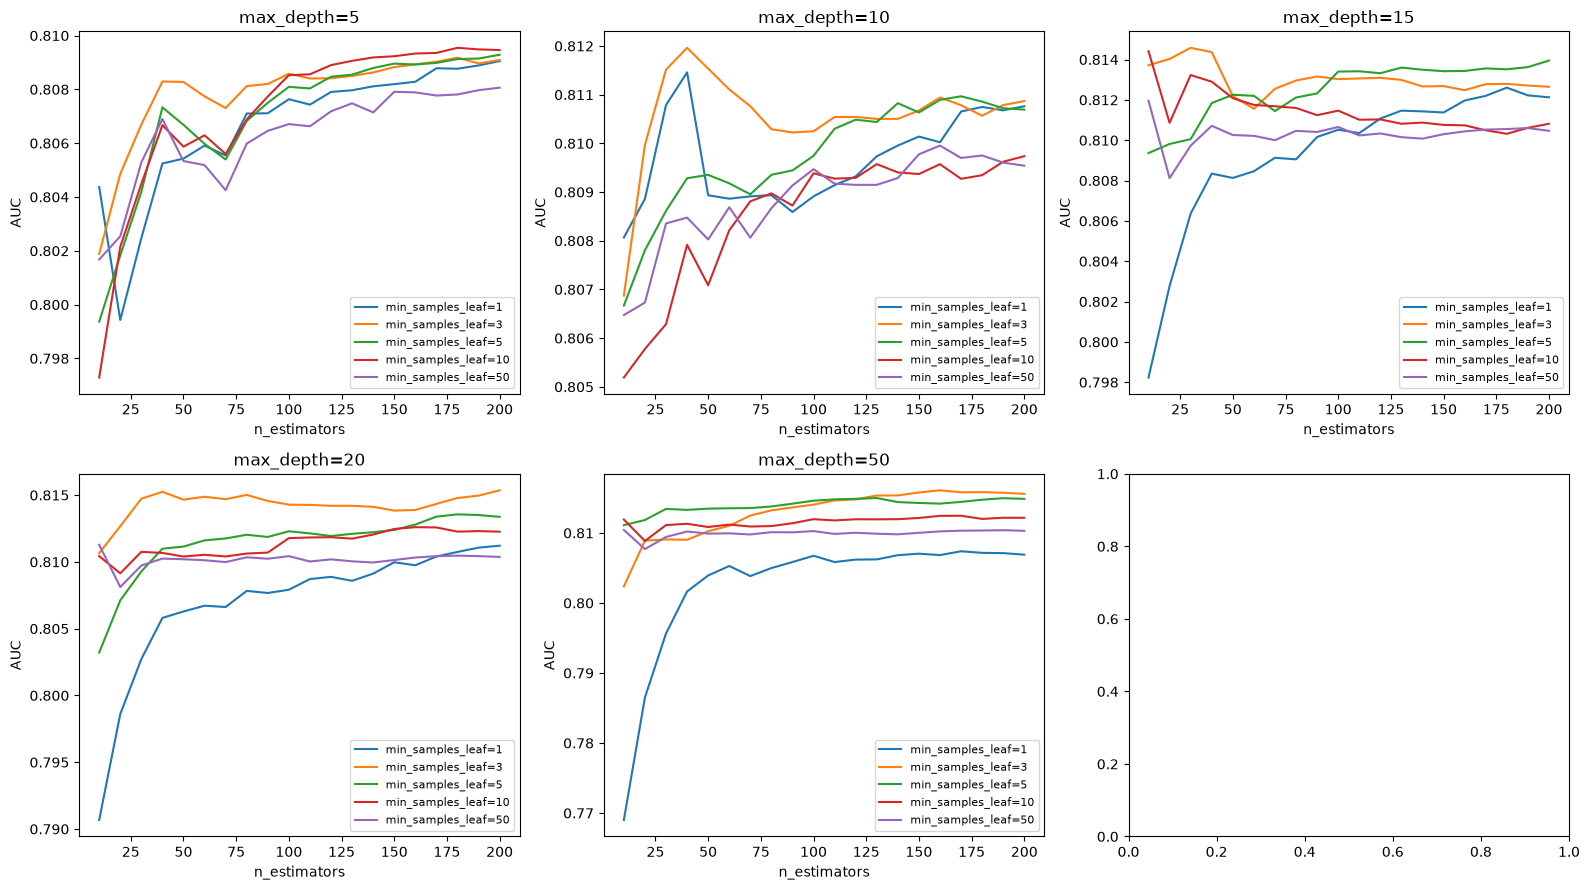

In [20]:
scores = []

for d in [5, 10, 15, 20, 50]:
    for s in [1, 3, 5, 10, 50]:
        for n in range(10, 201, 10):

            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=d,
                min_samples_leaf=s,
                random_state=1
            )

            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)

            scores.append((d, s, n, auc))

df_scores = pd.DataFrame(
    scores,
    columns=['max_depth', 'min_samples_leaf', 'n_estimators', 'auc']
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, d in enumerate([5, 10, 15, 20, 50]):
    ax = axes[i]
    df_depth = df_scores[df_scores.max_depth == d]
    for s in [1, 3, 5, 10, 50]:
        df_subset = df_depth[df_depth.min_samples_leaf == s]
        ax.plot(df_subset.n_estimators,df_subset.auc,label='min_samples_leaf=%d' % s)

    ax.set_title('max_depth=%d' % d)
    ax.set_xlabel('n_estimators')
    ax.set_ylabel('AUC')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [21]:
df_scores.sort_values('auc', ascending=False).head(10).reset_index(drop=True)

,max_depth,min_samples_leaf,n_estimators,auc
0,50,3,160,0.816092
1,50,3,180,0.815835
2,50,3,170,0.815809
3,50,3,150,0.815788
4,50,3,190,0.815744
5,50,3,200,0.815587
6,50,3,140,0.815360
7,20,3,200,0.815360
8,50,3,130,0.815349
9,20,3,40,0.815248


##### max_depth=50, min_samples_leaf=3, n_estimators=160 => auc=81.6

## XGBoost

In [22]:
import xgboost as xgb

In [23]:
features = dv.get_feature_names_out().tolist()
dtrain = xgb.DMatrix(X_train,label = y_train, feature_names=features)
dval = xgb.DMatrix(X_val,label=y_val,feature_names=features)

In [24]:
watchlist = [(dtrain, 'dtrain'),(dval, 'dval')]

In [141]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,

    'subsample': 0.7,
    'colsample_bytree': 1.0,

    'lambda': 1,
    'alpha': 0.01,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [26]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [27]:
df_score = parse_xgb_output(output)

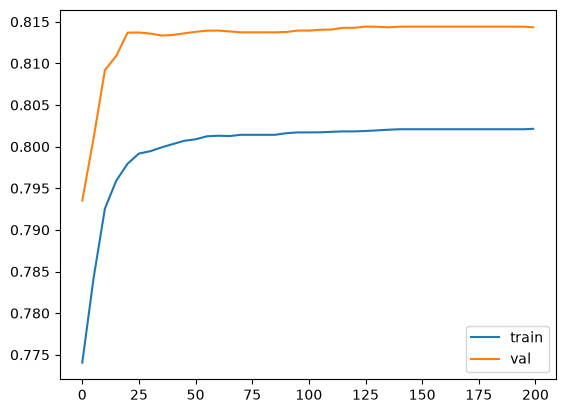

In [28]:
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

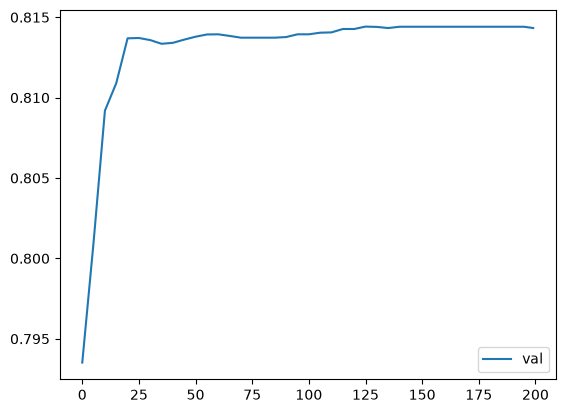

In [29]:
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

### eta

In [45]:
scores = {}

In [56]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
scores

{'eta=0.01':     num_iter  train_auc  val_auc
 0          0    0.80568  0.80756
 1          5    0.80694  0.80849
 2         10    0.80868  0.80917
 3         15    0.81063  0.81009
 4         20    0.81373  0.81235
 5         25    0.81540  0.81330
 6         30    0.81785  0.81469
 7         35    0.81915  0.81557
 8         40    0.82031  0.81614
 9         45    0.82131  0.81689
 10        50    0.82193  0.81693
 11        55    0.82293  0.81724
 12        60    0.82352  0.81753
 13        65    0.82440  0.81812
 14        70    0.82494  0.81828
 15        75    0.82541  0.81835
 16        80    0.82631  0.81877
 17        85    0.82721  0.81923
 18        90    0.82826  0.82026
 19        95    0.82904  0.82007
 20       100    0.82964  0.82029
 21       105    0.83012  0.82042
 22       110    0.83086  0.82081
 23       115    0.83171  0.82096
 24       120    0.83216  0.82093
 25       125    0.83299  0.82114
 26       130    0.83367  0.82126
 27       135    0.83417  0.82134
 2

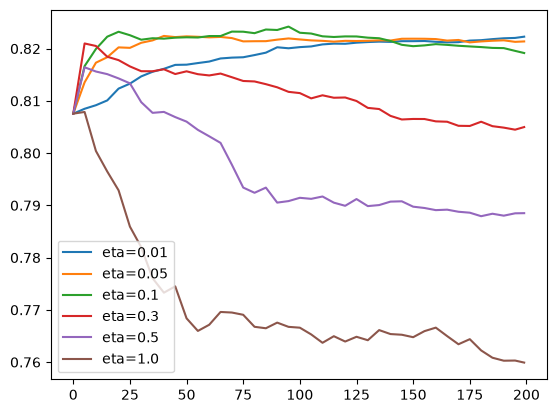

In [57]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)

plt.legend()
plt.show()

In [58]:
for eta, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(eta, best.num_iter, best.val_auc)

eta=0.01 199.0 0.82229
eta=0.05 40.0 0.82243
eta=0.1 95.0 0.82422
eta=0.3 5.0 0.82099
eta=0.5 5.0 0.81643
eta=1.0 5.0 0.80788


##### max auc=82.4% at eta=0.1 at 95 iterations

### max_depth

In [60]:
scores = {}

In [69]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
scores

{'max_depth=3':     num_iter  train_auc  val_auc
 0          0    0.77864  0.79458
 1          5    0.78793  0.80494
 2         10    0.79163  0.80756
 3         15    0.79445  0.80883
 4         20    0.79831  0.81154
 5         25    0.80075  0.81256
 6         30    0.80261  0.81303
 7         35    0.80479  0.81418
 8         40    0.80680  0.81464
 9         45    0.80830  0.81557
 10        50    0.81069  0.81673
 11        55    0.81186  0.81715
 12        60    0.81279  0.81770
 13        65    0.81367  0.81829
 14        70    0.81464  0.81835
 15        75    0.81556  0.81866
 16        80    0.81602  0.81880
 17        85    0.81670  0.81911
 18        90    0.81752  0.81919
 19        95    0.81818  0.81926
 20       100    0.81886  0.81979
 21       105    0.81967  0.81967
 22       110    0.82026  0.81972
 23       115    0.82055  0.81984
 24       120    0.82144  0.81988
 25       125    0.82187  0.81991
 26       130    0.82237  0.82004
 27       135    0.82301  0.82012

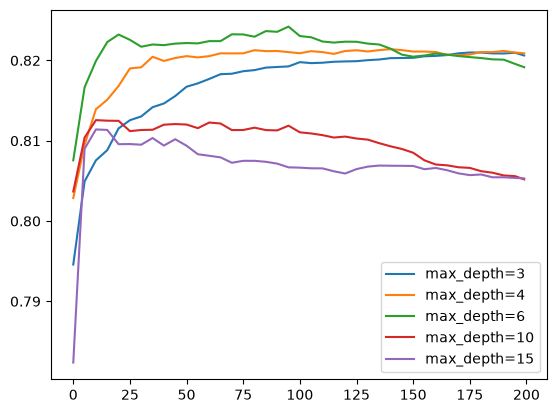

In [70]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)

plt.legend()
plt.show()

In [71]:
for max_depth, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(max_depth, best.num_iter, best.val_auc)

max_depth=3 175.0 0.82099
max_depth=4 140.0 0.82141
max_depth=6 95.0 0.82422
max_depth=10 10.0 0.81257
max_depth=15 10.0 0.81141


##### max_depth=6 gives auc=82.4% at 95 iterations

### min_child_weight

In [72]:
scores = {}

In [80]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
scores

{'min_child_weight=1':     num_iter  train_auc  val_auc
 0          0    0.80568  0.80756
 1          5    0.82167  0.81666
 2         10    0.82888  0.81994
 3         15    0.83511  0.82229
 4         20    0.84034  0.82323
 5         25    0.84590  0.82257
 6         30    0.85054  0.82171
 7         35    0.85493  0.82199
 8         40    0.85870  0.82191
 9         45    0.86052  0.82210
 10        50    0.86169  0.82217
 11        55    0.86345  0.82213
 12        60    0.86529  0.82241
 13        65    0.86682  0.82241
 14        70    0.86961  0.82326
 15        75    0.87181  0.82324
 16        80    0.87340  0.82296
 17        85    0.87528  0.82366
 18        90    0.87680  0.82357
 19        95    0.87861  0.82422
 20       100    0.88027  0.82304
 21       105    0.88157  0.82289
 22       110    0.88244  0.82236
 23       115    0.88355  0.82223
 24       120    0.88494  0.82234
 25       125    0.88629  0.82233
 26       130    0.88720  0.82210
 27       135    0.88818  

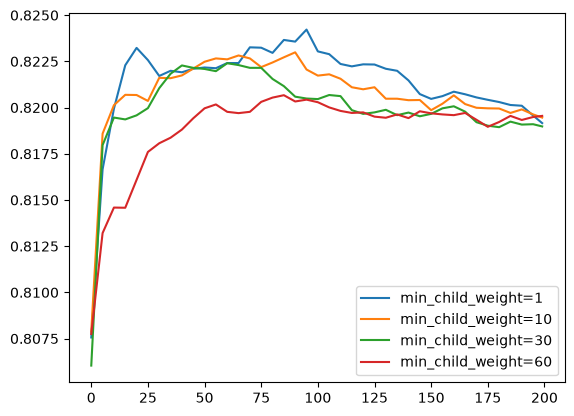

In [81]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)

plt.legend()
plt.show()

In [82]:
for min_child_weight, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(min_child_weight, best.num_iter, best.val_auc)

min_child_weight=1 95.0 0.82422
min_child_weight=10 90.0 0.82299
min_child_weight=30 60.0 0.8224
min_child_weight=60 85.0 0.82067


##### auc=82.4% at min_child_weight=1, at 95 iterations

### subsample

In [84]:
scores = {}

In [95]:
key = 'subsample=%s' % (xgb_params['subsample'])
scores[key] = parse_xgb_output(output)
scores

{'subsample=0.5':     num_iter  train_auc  val_auc
 0          0    0.79266  0.79602
 1          5    0.81984  0.81518
 2         10    0.82774  0.81791
 3         15    0.83419  0.81911
 4         20    0.83908  0.81667
 5         25    0.84536  0.81471
 6         30    0.84858  0.81541
 7         35    0.85030  0.81622
 8         40    0.85344  0.81598
 9         45    0.85588  0.81545
 10        50    0.85920  0.81700
 11        55    0.86184  0.81706
 12        60    0.86400  0.81656
 13        65    0.86675  0.81577
 14        70    0.87041  0.81590
 15        75    0.87268  0.81602
 16        80    0.87415  0.81464
 17        85    0.87686  0.81396
 18        90    0.87912  0.81463
 19        95    0.88145  0.81523
 20       100    0.88332  0.81549
 21       105    0.88497  0.81599
 22       110    0.88686  0.81611
 23       115    0.88861  0.81644
 24       120    0.89152  0.81622
 25       125    0.89291  0.81551
 26       130    0.89445  0.81604
 27       135    0.89611  0.815

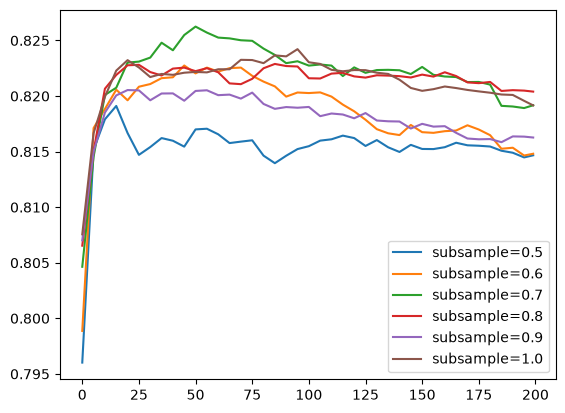

In [96]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)

plt.legend()
plt.show()

In [97]:
for subsample, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(subsample, best.num_iter, best.val_auc)

subsample=0.5 15.0 0.81911
subsample=0.6 45.0 0.82275
subsample=0.7 50.0 0.82625
subsample=0.8 85.0 0.82289
subsample=0.9 20.0 0.82054
subsample=1.0 95.0 0.82422


##### auc=82.6%, subsample=0.7, iterations=50

### colsample_bytree

In [98]:
scores = {}

In [112]:
key = 'colsample_bytree=%s' % (xgb_params['colsample_bytree'])
scores[key] = parse_xgb_output(output)
scores

{'colsample_bytree=0.4':     num_iter  train_auc  val_auc
 0          0    0.67117  0.64495
 1          5    0.81363  0.80883
 2         10    0.81750  0.81067
 3         15    0.82202  0.81082
 4         20    0.82840  0.81281
 5         25    0.83267  0.81277
 6         30    0.83488  0.81219
 7         35    0.83979  0.81238
 8         40    0.84245  0.81319
 9         45    0.84550  0.81490
 10        50    0.84857  0.81430
 11        55    0.85071  0.81492
 12        60    0.85344  0.81482
 13        65    0.85521  0.81480
 14        70    0.85814  0.81476
 15        75    0.86066  0.81423
 16        80    0.86178  0.81462
 17        85    0.86269  0.81472
 18        90    0.86474  0.81456
 19        95    0.86712  0.81421
 20       100    0.86961  0.81392
 21       105    0.87068  0.81497
 22       110    0.87235  0.81454
 23       115    0.87419  0.81414
 24       120    0.87520  0.81441
 25       125    0.87625  0.81469
 26       130    0.87795  0.81444
 27       135    0.87926

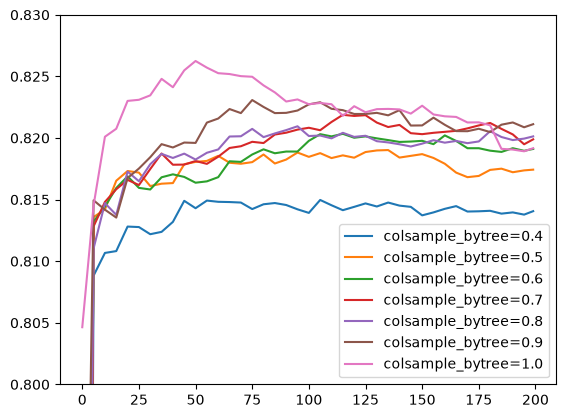

In [113]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)
plt.ylim(0.8,0.83)
plt.legend()
plt.show()

In [114]:
for colsample_bytree, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(colsample_bytree, best.num_iter, best.val_auc)

colsample_bytree=0.4 105.0 0.81497
colsample_bytree=0.5 135.0 0.81902
colsample_bytree=0.6 115.0 0.82034
colsample_bytree=0.7 115.0 0.82188
colsample_bytree=0.8 95.0 0.82095
colsample_bytree=0.9 75.0 0.82308
colsample_bytree=1.0 50.0 0.82625


##### auc=82.6, colsample_bytree=1.0, 50 iterations

### lambda

In [116]:
scores = {}

In [127]:
key = 'lambda=%s' % (xgb_params['lambda'])
scores[key] = parse_xgb_output(output)
scores

{'lambda=0':     num_iter  train_auc  val_auc
 0          0    0.80174  0.79211
 1          5    0.82379  0.81202
 2         10    0.83027  0.81809
 3         15    0.83895  0.81778
 4         20    0.84418  0.82074
 5         25    0.85022  0.82087
 6         30    0.85534  0.82002
 7         35    0.85904  0.82008
 8         40    0.86120  0.82044
 9         45    0.86312  0.82088
 10        50    0.86594  0.82136
 11        55    0.86853  0.82132
 12        60    0.87096  0.82083
 13        65    0.87298  0.82115
 14        70    0.87530  0.82150
 15        75    0.87710  0.82146
 16        80    0.87913  0.82059
 17        85    0.88211  0.81992
 18        90    0.88478  0.81909
 19        95    0.88702  0.81868
 20       100    0.88925  0.81758
 21       105    0.89117  0.81767
 22       110    0.89298  0.81700
 23       115    0.89526  0.81674
 24       120    0.89672  0.81746
 25       125    0.89871  0.81687
 26       130    0.90045  0.81581
 27       135    0.90254  0.81636
 2

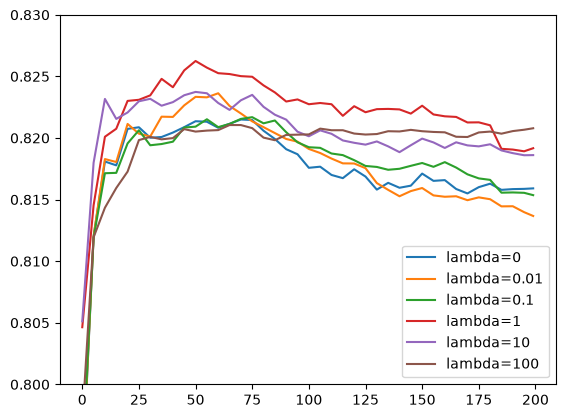

In [128]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)
plt.ylim(0.8,0.83)
plt.legend()
plt.show()

In [129]:
for lam, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(lam, best.num_iter, best.val_auc)

lambda=0 70.0 0.8215
lambda=0.01 60.0 0.82363
lambda=0.1 75.0 0.82169
lambda=1 50.0 0.82625
lambda=10 50.0 0.82374
lambda=100 65.0 0.82105


##### auc=82.6%, lambda=1, 50 iterations

### alpha

In [131]:
scores = {}

In [142]:
key = 'alpha=%s' % (xgb_params['alpha'])
scores[key] = parse_xgb_output(output)
scores

{'alpha=0':     num_iter  train_auc  val_auc
 0          0    0.79885  0.80464
 1          5    0.82200  0.81454
 2         10    0.82845  0.82010
 3         15    0.83627  0.82075
 4         20    0.84107  0.82301
 5         25    0.84620  0.82310
 6         30    0.85085  0.82346
 7         35    0.85471  0.82480
 8         40    0.85751  0.82412
 9         45    0.86036  0.82549
 10        50    0.86284  0.82625
 11        55    0.86530  0.82571
 12        60    0.86711  0.82526
 13        65    0.86928  0.82519
 14        70    0.87251  0.82502
 15        75    0.87417  0.82497
 16        80    0.87570  0.82427
 17        85    0.87896  0.82370
 18        90    0.88098  0.82296
 19        95    0.88264  0.82313
 20       100    0.88451  0.82274
 21       105    0.88612  0.82284
 22       110    0.88818  0.82274
 23       115    0.89117  0.82180
 24       120    0.89296  0.82258
 25       125    0.89458  0.82209
 26       130    0.89607  0.82234
 27       135    0.89769  0.82236
 28

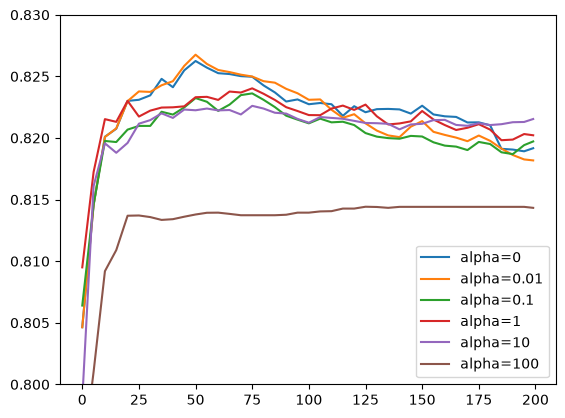

In [143]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter,df_score.val_auc,label=key)
plt.ylim(0.8,0.83)
plt.legend()
plt.show()

In [144]:
for alpha, df_score in scores.items():
    best = df_score.loc[df_score.val_auc.idxmax()]
    print(alpha, best.num_iter, best.val_auc)

alpha=0 50.0 0.82625
alpha=0.01 50.0 0.82676
alpha=0.1 75.0 0.82362
alpha=1 75.0 0.82403
alpha=10 75.0 0.82261
alpha=100 125.0 0.81442


##### auc=82.6%, alpha=0.01, 50 iterations

## best model

In [145]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,

    'subsample': 0.7,
    'colsample_bytree': 1.0,

    'lambda': 1,
    'alpha': 0.01,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=95,
                  verbose_eval=5,
                  evals=watchlist)

[0]	dtrain-auc:0.79885	dval-auc:0.80464
[5]	dtrain-auc:0.82198	dval-auc:0.81457
[10]	dtrain-auc:0.82842	dval-auc:0.82008
[15]	dtrain-auc:0.83626	dval-auc:0.82078
[20]	dtrain-auc:0.84107	dval-auc:0.82299
[25]	dtrain-auc:0.84639	dval-auc:0.82378
[30]	dtrain-auc:0.85135	dval-auc:0.82374
[35]	dtrain-auc:0.85523	dval-auc:0.82428
[40]	dtrain-auc:0.85811	dval-auc:0.82461
[45]	dtrain-auc:0.86078	dval-auc:0.82585
[50]	dtrain-auc:0.86303	dval-auc:0.82676
[55]	dtrain-auc:0.86548	dval-auc:0.82601
[60]	dtrain-auc:0.86746	dval-auc:0.82552
[65]	dtrain-auc:0.86911	dval-auc:0.82535
[70]	dtrain-auc:0.87311	dval-auc:0.82514
[75]	dtrain-auc:0.87469	dval-auc:0.82499
[80]	dtrain-auc:0.87624	dval-auc:0.82461
[85]	dtrain-auc:0.87970	dval-auc:0.82449
[90]	dtrain-auc:0.88185	dval-auc:0.82399
[94]	dtrain-auc:0.88359	dval-auc:0.82358


In [146]:
y_pred = model.predict(dval)
roc_auc_score(y_val,y_pred)

0.8235778616104982

# final model

In [147]:
df_full_train = pd.concat([df_train, df_val])
y_full_train = np.concatenate([y_train, y_val])

In [148]:
dicts_full_train = df_full_train.to_dict(orient='records')

In [149]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

In [150]:
df_test = pd.read_csv(DATA_DIR / 'test.csv')

In [151]:
dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [152]:
dfulltrain = xgb.DMatrix(X_full_train,label=y_full_train, feature_names=dv.get_feature_names_out().tolist())
dtest = xgb.DMatrix(X_test, feature_names=dv.get_feature_names_out().tolist())

In [153]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,

    'subsample': 0.7,
    'colsample_bytree': 1.0,

    'lambda': 1,
    'alpha': 0.01,
    
    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}
model = xgb.train(xgb_params, dfulltrain, num_boost_round=95)

In [154]:
y_pred = model.predict(dtest)

In [155]:
import pickle

output_file = PROJECT_DIR / 'model.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)

In [156]:
print(output_file.resolve())
print(output_file.exists())

/workspaces/seeking-job-change-prediction/model.bin
True
